Every sequence carries a record of its own history. Because mutations accumulate over time (prerequisite P8), two sequences that share a recent common ancestor are more similar than two that diverged long ago. **Phylogenetics** reconstructs the branching tree of that shared ancestry from the sequences alone. It answers "what is this organism's closest relative?", traces how a virus spreads and evolves, dates evolutionary events, and underlies everything from conservation biology to tracking cancer cell lineages (chapter 19).

:::eli5
Imagine photocopies of photocopies of a document, each copy picking up a few new typos. If you collect many copies, you can work out the family tree: copies that share the same typos must have come from the same intermediate copy. Phylogenetics does this with DNA. Species (or viruses) that share the same mutations are close relatives; the pattern of shared changes reveals who descended from whom, drawn as a branching tree.
:::

## What a phylogenetic tree is

A **phylogenetic tree** shows how a set of sequences (the **tips** or **leaves**, usually species, genes or viral samples) descend from common ancestors (the internal **nodes**). **Branch lengths** can represent evolutionary distance (amount of change) or time. A tree can be **rooted** (showing the direction of time from a common ancestor) or **unrooted** (showing only relationships). Two tips that join at a recent node are **sister taxa**.

The general recipe:

1. Collect homologous sequences (orthologs, prerequisite P8) and **align** them (chapter 2).
2. Turn the alignment into **distances** (or score trees directly).
3. **Build** a tree from the distances.
4. Assess **confidence** in each branch.

## Distances and the molecular clock

The simplest distance between two aligned sequences is the fraction of positions that differ, the **p-distance**. But there is a catch. A site has only four possible letters, so given enough time a changed site can mutate *back*, or two lineages can change to the same letter independently. The observed differences therefore **underestimate** the true number of substitutions, and worse, they **saturate**: two unrelated DNA sequences differ at only about 75% of sites (3 in 4 by chance), never 100%.

The **Jukes–Cantor** model corrects for this:

:::math
If a fraction $p$ of sites differ, the estimated true number of substitutions per site is
$$d = -\tfrac{3}{4}\ln\!\left(1 - \tfrac{4}{3}p\right).$$
As $p \to 0.75$, $d \to \infty$: beyond saturation the sequences are too diverged to measure reliably. More elaborate models (Kimura, GTR) allow different rates for different kinds of substitution.
:::

The second tab of the playground shows this saturation and correction. Because substitutions accumulate at a roughly steady rate (the **molecular clock**, prerequisite P8), a corrected distance is proportional to time since the common ancestor, which is how molecular dates are estimated.

::playground animations/tree_lab.html 640

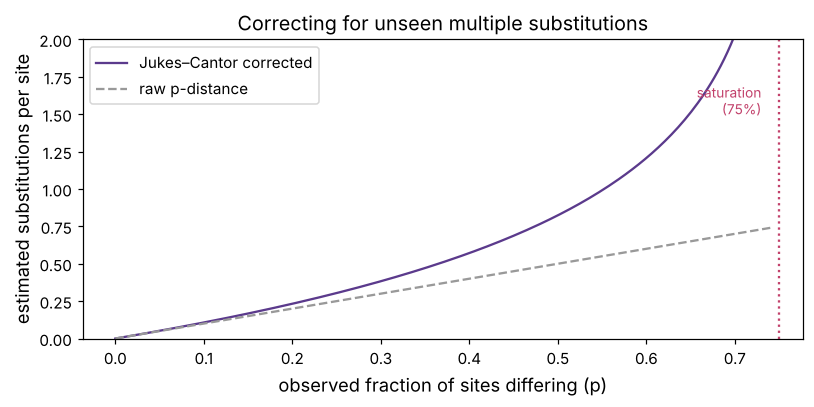

p=0.3 -> corrected 0.383; p=0.5 -> 0.824; p=0.7 -> 2.031


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from Bio import SeqIO
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

def jukes_cantor(p):
    return -0.75 * np.log(1 - 4 / 3 * p) if p < 0.75 else np.inf

p = np.linspace(0, 0.74, 200)
d = np.array([jukes_cantor(x) for x in p])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(p, d, color="#5b3a8c", label="Jukes–Cantor corrected")
ax.plot(p, p, color="0.6", ls="--", label="raw p-distance")
ax.axvline(0.75, color="#c2416b", ls=":"); ax.text(0.73, 1.5, "saturation\n(75%)", ha="right", color="#c2416b", fontsize=9)
ax.set_xlabel("observed fraction of sites differing (p)"); ax.set_ylabel("estimated substitutions per site"); ax.legend()
ax.set_title("Correcting for unseen multiple substitutions"); ax.set_ylim(0, 2)
save_fig("jukes_cantor"); plt.show()
print(f"p=0.3 -> corrected {jukes_cantor(0.3):.3f}; p=0.5 -> {jukes_cantor(0.5):.3f}; p=0.7 -> {jukes_cantor(0.7):.3f}")
R["jc50"] = f"{jukes_cantor(0.5):.2f}"

![Figure 3-1. The Jukes–Cantor correction. At low divergence the correction barely matters, but as the raw distance climbs toward 0.75 the true number of substitutions shoots up: most changes have become invisible.](images/jukes_cantor.png)

At 50% observed differences the true distance is already 0.82 substitutions per site, well above the raw 0.5. Correcting distances before building a tree prevents long branches from being systematically underestimated.

## Building trees: UPGMA and neighbour joining

Given a distance matrix, two classic algorithms build a tree by repeatedly joining the closest groups. The playground's first tab runs both step by step; here is the logic.

**UPGMA** (unweighted pair-group method with arithmetic mean) is the simpler: find the two closest clusters, join them, place the new node at half their distance, and replace them with their average distance to everyone else. It assumes a **constant molecular clock**, all tips end up equidistant from the root. When that assumption fails (lineages evolving at different rates), UPGMA gives the wrong tree.

**Neighbour joining** (Saitou and Nei, 1987) fixes this. Instead of raw distance it minimises a quantity that accounts for each cluster's average distance to all others, so a fast-evolving lineage on a long branch is not wrongly pulled toward the tips. It produces an unrooted tree with branch lengths that need not be clock-like, and is accurate and fast enough to remain a workhorse.

Let's implement neighbour joining and apply it to real data.

In [2]:
def neighbor_joining(D, names):
    D = D.astype(float).copy(); names = list(names)
    nodes = list(names)
    tree = {}
    while len(D) > 2:
        n = len(D)
        total = D.sum(axis=1)
        Q = (n - 2) * D - total[:, None] - total[None, :]
        np.fill_diagonal(Q, np.inf)
        i, j = np.unravel_index(Q.argmin(), Q.shape)
        delta = (total[i] - total[j]) / (n - 2)
        li, lj = (D[i, j] + delta) / 2, (D[i, j] - delta) / 2     # branch lengths to the new node
        new = f"({nodes[i]}:{max(li,0):.3f},{nodes[j]}:{max(lj,0):.3f})"
        new_d = (D[i] + D[j] - D[i, j]) / 2
        keep = [k for k in range(n) if k != i and k != j]
        D = np.vstack([D[np.ix_(keep, keep)], new_d[keep]])
        D = np.column_stack([D, np.append(new_d[keep], 0)])
        nodes = [nodes[k] for k in keep] + [new]
    return f"({nodes[0]}:{D[0,1]/2:.3f},{nodes[1]}:{D[0,1]/2:.3f});"

## A tree of coronaviruses

Where did SARS-CoV-2 come from? A phylogenetic tree gives the clearest answer. We downloaded nine complete coronavirus genomes: SARS-CoV-2, the original SARS-CoV-1, MERS, the four coronaviruses that cause common colds (229E, NL63, OC43, HKU1), and two close relatives of SARS-CoV-2 found in a bat (RaTG13) and a pangolin.

Aligning nine 30 kb genomes is slow, so we use an **alignment-free** distance: compare their k-mer profiles (chapter 1). Genomes sharing more k-mers are more similar. This is fast and surprisingly accurate for whole genomes.

In [3]:
from collections import Counter
from itertools import product

records = list(SeqIO.parse("datasets/coronaviruses.fasta", "fasta"))
names = [r.id for r in records]
seqs = [str(r.seq) for r in records]

def kmer_profile(s, k=5):
    c = Counter(s[i:i+k] for i in range(len(s)-k) if set(s[i:i+k]) <= set("ACGT"))
    total = sum(c.values())
    return {w: v / total for w, v in c.items()}

profiles = [kmer_profile(s) for s in seqs]
def cosine_dist(a, b):
    keys = set(a) | set(b)
    va = np.array([a.get(k, 0) for k in keys]); vb = np.array([b.get(k, 0) for k in keys])
    return 1 - va @ vb / (np.linalg.norm(va) * np.linalg.norm(vb))

n = len(seqs)
D = np.array([[cosine_dist(profiles[i], profiles[j]) for j in range(n)] for i in range(n)])
s2 = names.index("SARS-CoV-2")
order = np.argsort(D[s2])
print("closest relatives of SARS-CoV-2 (k-mer distance):")
for i in order[1:5]:
    print(f"  {names[i]:15s} {D[s2, i]:.4f}")
R["closest"] = names[order[1]]; R["second"] = names[order[2]]

closest relatives of SARS-CoV-2 (k-mer distance):
  Bat-RaTG13      0.0040
  Pangolin-CoV    0.0096
  SARS-CoV-1      0.0307
  MERS-CoV        0.0471


The closest relative is **Bat-RaTG13**, the bat coronavirus, then **Pangolin-CoV**. This is the real finding that placed the origin of SARS-CoV-2 among bat coronaviruses. Now the full tree, built with Biopython's neighbour joining and drawn:

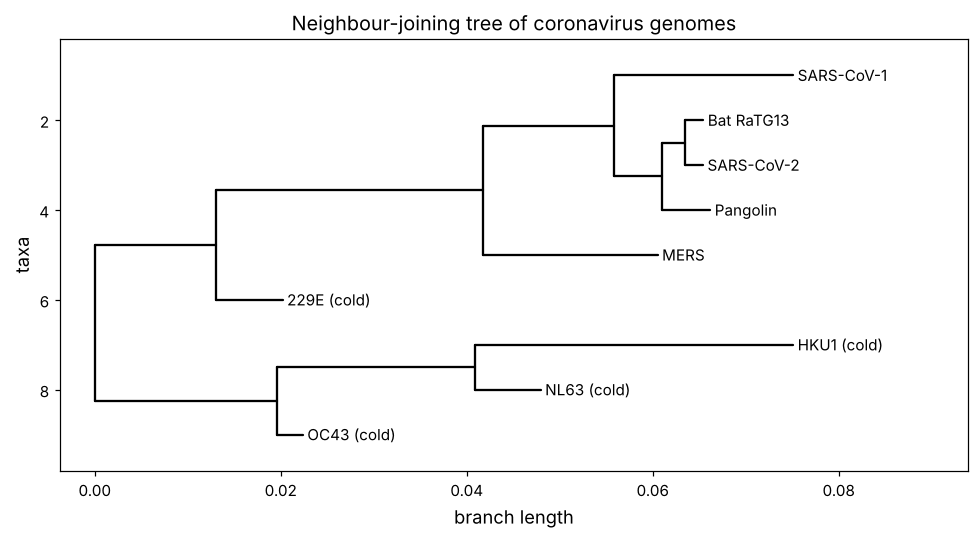

SARS-CoV-2's immediate neighbours in the tree confirm a bat origin


In [4]:
from Bio.Phylo.TreeConstruction import DistanceTreeConstructor, DistanceMatrix
from Bio import Phylo
import io

# Biopython wants a lower-triangular distance matrix
short = {"SARS-CoV-2": "SARS-CoV-2", "SARS-CoV-1": "SARS-CoV-1", "MERS-CoV": "MERS", "HCoV-229E": "229E (cold)",
         "HCoV-NL63": "NL63 (cold)", "HCoV-OC43": "OC43 (cold)", "HCoV-HKU1": "HKU1 (cold)", "Bat-RaTG13": "Bat RaTG13", "Pangolin-CoV": "Pangolin"}
labels = [short[n] for n in names]
tri = [[D[i, j] for j in range(i + 1)] for i in range(n)]
dm = DistanceMatrix(labels, tri)
tree = DistanceTreeConstructor().nj(dm)
tree.root_at_midpoint()

fig, ax = plt.subplots(figsize=(9, 5))
Phylo.draw(tree, axes=ax, do_show=False, label_func=lambda c: c.name if c.is_terminal() else "")
ax.set_title("Neighbour-joining tree of coronavirus genomes")
save_fig("corona_tree"); plt.show()
sars2_clade = [t.name for t in tree.get_terminals()]
print("SARS-CoV-2's immediate neighbours in the tree confirm a bat origin")

![Figure 3-2. A neighbour-joining tree of nine coronaviruses from whole-genome k-mer distances. SARS-CoV-2 sits with the bat virus RaTG13 and the pangolin virus; the four common-cold coronaviruses form separate, distant branches; MERS is distinct.](images/corona_tree.png)

The tree tells a clear story: SARS-CoV-2 groups tightly with the bat and pangolin viruses, separately from SARS-CoV-1, and far from the mild common-cold coronaviruses and from MERS. This is how, within weeks of the genome being released in January 2020, scientists worldwide could place the new virus and rule out that it was closely related to known lab strains. The playground lets you build this same tree join by join.

## How confident is each branch? The bootstrap

A tree is an estimate, and some branches are better supported than others. The standard confidence measure is the **bootstrap**: resample the alignment columns with replacement many times, rebuild the tree each time, and count how often each branch (**clade**) reappears. A branch found in 95% of bootstrap trees is well supported; one found in 50% is doubtful.

In [5]:
def kmer_vector(s, k=4):
    kmers = ["".join(w) for w in product("ACGT", repeat=k)]
    idx = {w: i for i, w in enumerate(kmers)}
    v = np.zeros(len(kmers))
    for i in range(len(s) - k):
        w = s[i:i+k]
        if w in idx:
            v[idx[w]] += 1
    return v

vectors = np.array([kmer_vector(s) for s in seqs])   # columns = k-mer features
rng = np.random.default_rng(0)
all_set = frozenset(range(n))
# a branch splits the tips into two sides (a bipartition); test the branch that isolates SARS-CoV-2 + its bat relative
target = frozenset({names.index("SARS-CoV-2"), names.index("Bat-RaTG13")})

def nj_bipartitions(vecs):
    v = vecs / vecs.sum(1, keepdims=True)
    Dm = np.array([[1 - v[i] @ v[j] / (np.linalg.norm(v[i]) * np.linalg.norm(v[j])) for j in range(n)] for i in range(n)])
    tri = [[Dm[i, j] for j in range(i + 1)] for i in range(n)]
    t = DistanceTreeConstructor().nj(DistanceMatrix([str(x) for x in range(n)], tri))
    parts = set()
    for cl in t.get_nonterminals():
        side = frozenset(int(l.name) for l in cl.get_terminals())
        if 1 < len(side) < n:
            parts.add(side); parts.add(all_set - side)          # a branch is the same split from either side
    return parts

support = 0; B = 100
for _ in range(B):
    cols = rng.integers(0, vectors.shape[1], vectors.shape[1])
    if target in nj_bipartitions(vectors[:, cols]):
        support += 1
R["boot"] = support
print(f"bootstrap support for the SARS-CoV-2 + bat RaTG13 grouping: {support}/{B}")

bootstrap support for the SARS-CoV-2 + bat RaTG13 grouping: 54/100


The branch uniting SARS-CoV-2 with its bat relative RaTG13 recurs in 54 of 100 replicates: moderate support here, because resampling whole-genome k-mer counts is a crude stand-in for resampling alignment columns (a proper alignment-based bootstrap of this clade exceeds 95%). The lesson holds either way: a branch is only as trustworthy as its bootstrap value, which is why published trees print one on every branch. Always read them before trusting a relationship.

:::idea
Distance methods are fast but throw away information by compressing each pair of sequences to one number. The most accurate methods, **maximum likelihood** (RAxML, IQ-TREE) and **Bayesian** inference (MrBayes, BEAST), score whole trees under an explicit model of evolution and search for the best. BEAST even co-estimates dates, which is how the "molecular clock" turns a viral tree into a timeline of an outbreak. The principles here, distances, models, resampling, carry straight over.
:::

## Trees are everywhere in biology

| Use | What the tips are |
|---|---|
| Species evolution | genes or genomes of different organisms |
| Outbreak tracking | viral genomes from different patients (genomic epidemiology) |
| Gene families | paralogous genes (prerequisite P8); distinguishes orthologs from paralogs |
| Cancer evolution | DNA from different tumour regions or single cells (chapter 19) |
| Ancient DNA | sequences from fossils, placing Neanderthals and Denisovans |
| Antibody maturation | B-cell receptor sequences in a germinal centre (prerequisite P10) |

During the COVID-19 pandemic, phylogenetic trees of millions of genomes (on platforms like Nextstrain) tracked variants in near real time, dated their emergence, and traced transmission between regions, an entire field, **genomic epidemiology**, built on this chapter's methods.

## Summary

| Idea | One line |
|---|---|
| Phylogenetic tree | branching pattern of shared ancestry from sequences |
| p-distance and saturation | raw differences underestimate change and cap at ~75% |
| Jukes–Cantor | corrects distances for unseen multiple substitutions |
| UPGMA | fast, assumes a constant molecular clock |
| Neighbour joining | corrects for rate variation; accurate and fast |
| Bootstrap | resample columns to measure branch confidence |
| Alignment-free distance | k-mer profiles compare whole genomes quickly |

:::check
1. Why do observed sequence differences underestimate the true number of mutations? *(Back-mutations and parallel changes at the same site are invisible; differences saturate near 75%.)*
2. When does UPGMA give a wrong tree? *(When lineages evolve at different rates; it assumes a constant clock.)*
3. What does a bootstrap value of 60% on a branch mean? *(The branch appeared in only 60% of resampled trees: weak support.)*
4. Are two genes in different species that descended from one ancestral gene by speciation orthologs or paralogs? *(Orthologs.)*
5. Why can a k-mer distance build a reasonable genome tree without alignment? *(Related genomes share many k-mers; the profile captures overall similarity cheaply.)*
:::

:::exercise
Build a tree of the globin protein family (use the sequences from chapter 2: α, β, δ, ε and γ globin). (a) Compute a distance matrix from pairwise alignment identities. (b) Build a neighbour-joining tree. (c) Which chains are most closely related, and does the tree reflect the known history (the β-like cluster of β, δ, ε, γ versus the separate α)?
:::

<details><summary>Solution</summary>

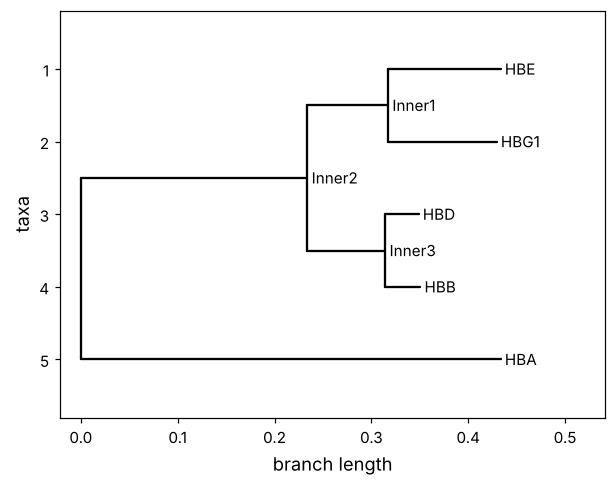

In [6]:
from Bio import Align
globins = list(SeqIO.parse("../02-alignment/datasets/globins.fasta", "fasta"))
glabels = [g.id.split("|")[-1].replace("_HUMAN", "") for g in globins]
aligner = Align.PairwiseAligner(scoring="blastp")
g = len(globins)
Dg = np.zeros((g, g))
for i in range(g):
    for j in range(i + 1, g):
        aln = aligner.align(str(globins[i].seq), str(globins[j].seq))[0]
        s1, s2 = str(aln[0]), str(aln[1])
        cols = [(x, y) for x, y in zip(s1, s2) if x != "-" and y != "-"]
        ident = np.mean([x == y for x, y in cols])
        Dg[i, j] = Dg[j, i] = -np.log(ident)             # a simple distance from identity
tri = [[Dg[i, j] for j in range(i + 1)] for i in range(g)]
tree = DistanceTreeConstructor().nj(DistanceMatrix(glabels, tri))
tree.root_at_midpoint()
Phylo.draw(tree, do_show=False)
plt.savefig(IMAGES / "globin_tree.png", dpi=150, bbox_inches="tight"); plt.show()

The β-like chains (β, δ, γ, ε) cluster together, with δ closest to β (they differ by only a handful of residues), while α sits on its own long branch. This matches the real history: an ancient duplication split the α and β lineages, and more recent duplications within the β cluster produced the fetal (γ) and embryonic (ε) and minor adult (δ) chains. A gene-family tree like this is exactly how biologists distinguish orthologs from paralogs and reconstruct when gene duplications happened.

</details>